   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
(150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.00

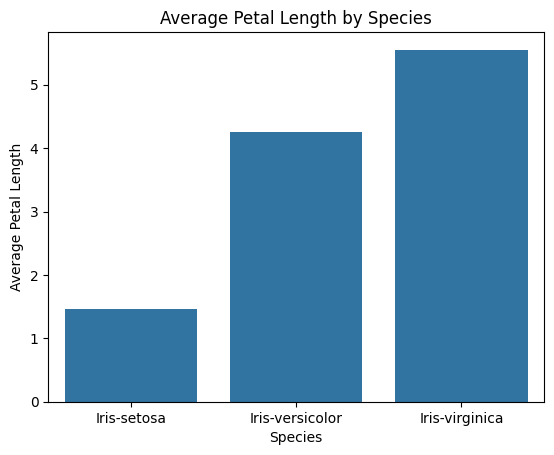

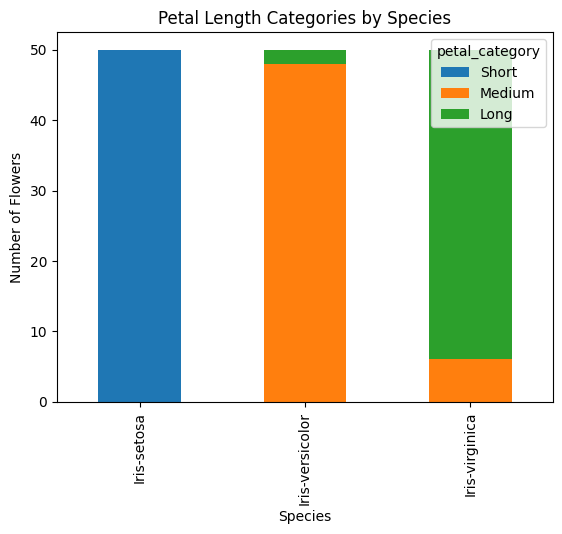

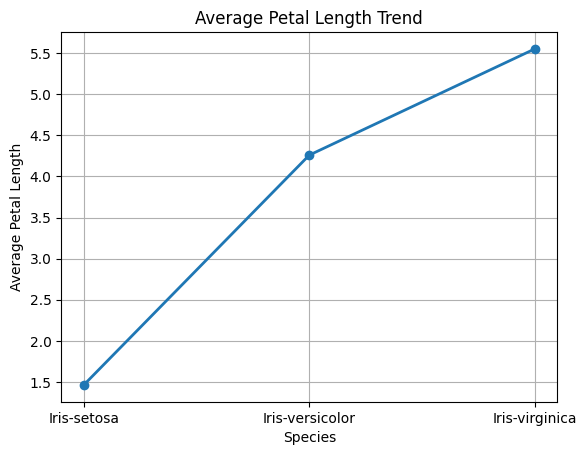

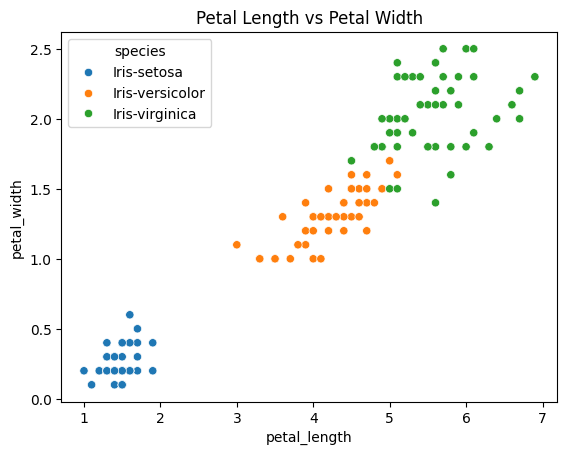

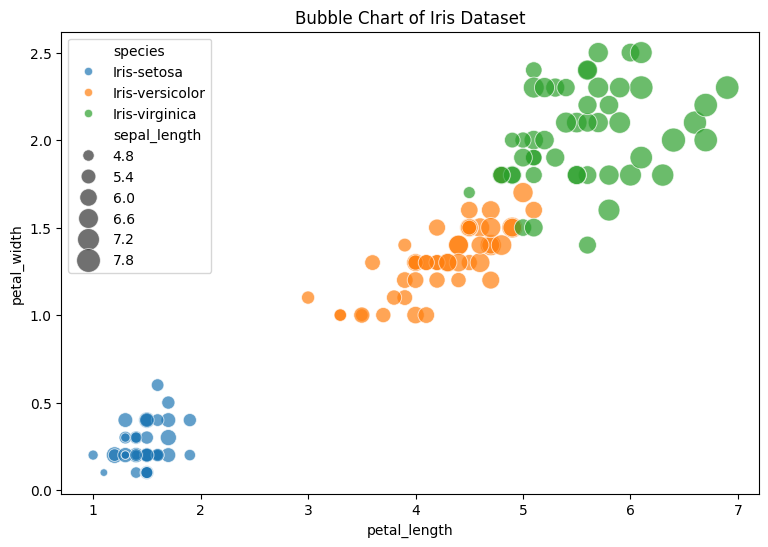

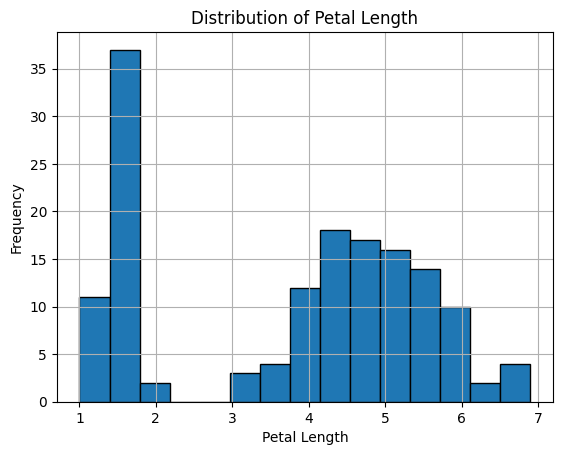

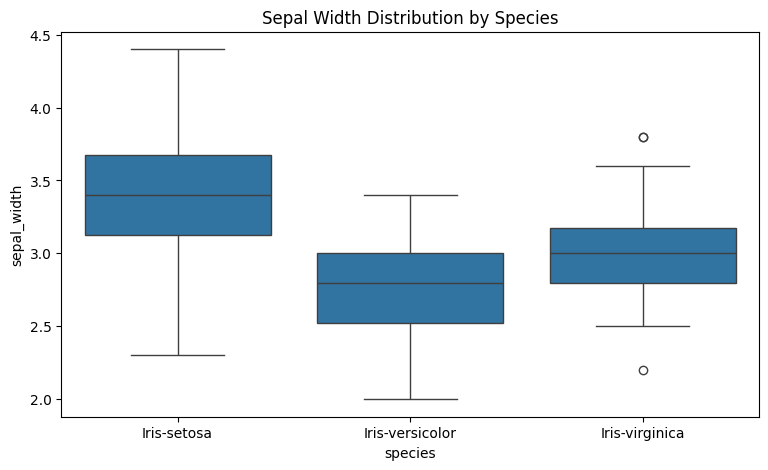

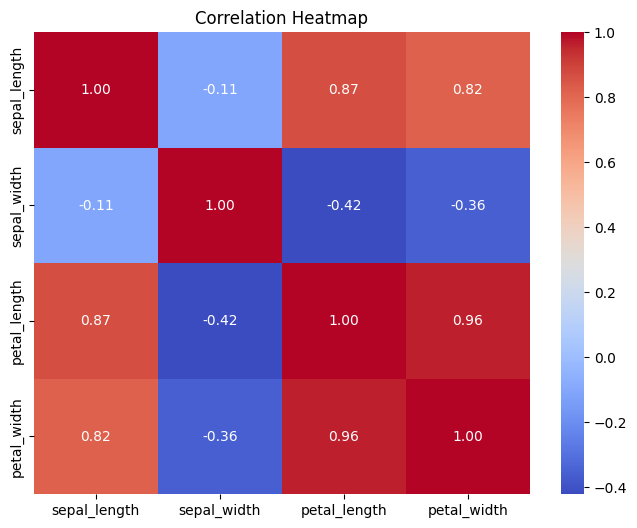

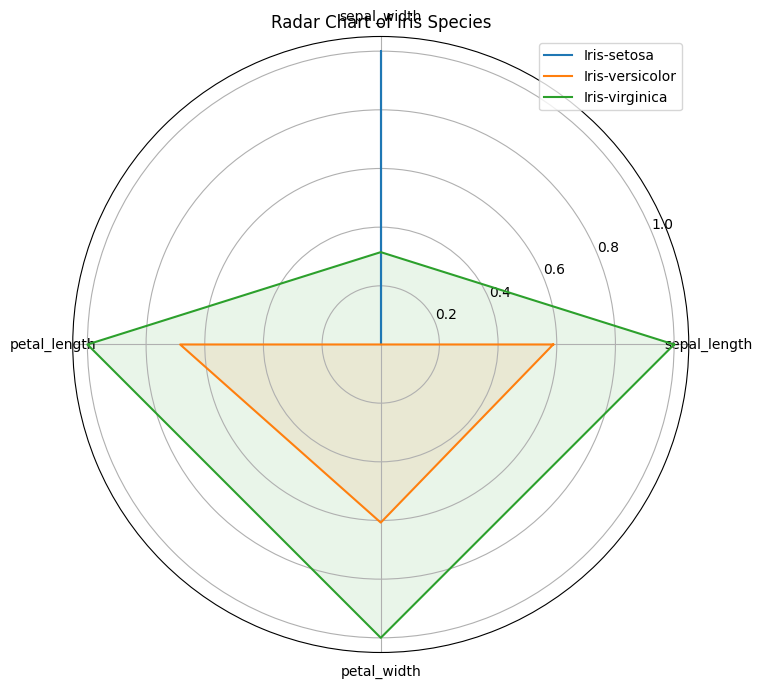

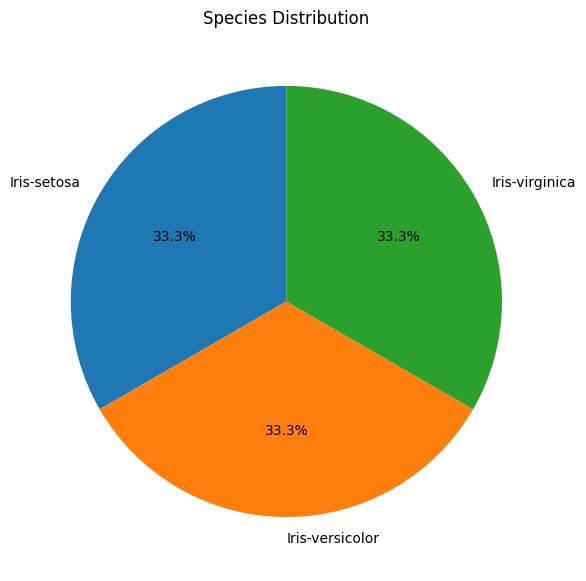

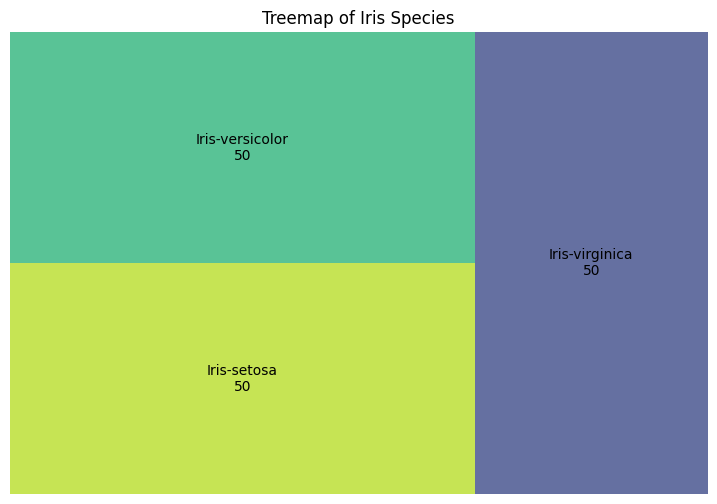

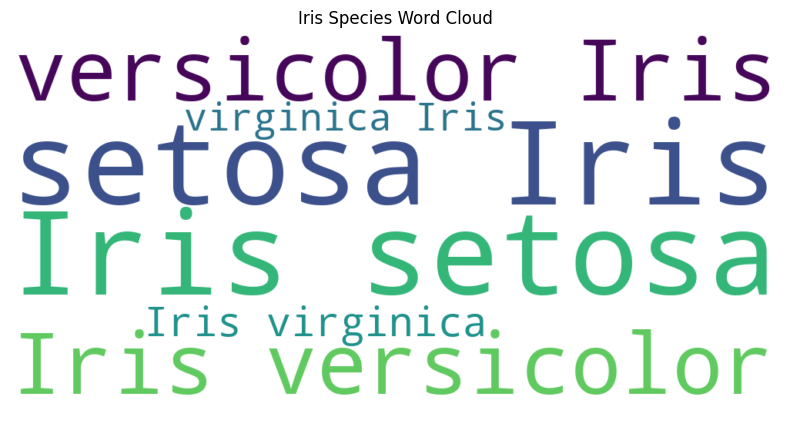

In [ ]:
!pip install -q wordcloud squarify
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

from wordcloud import WordCloud
from math import pi


df = pd.read_csv("/content/Iris.csv")

# Remove unnecessary ID column if present
df = df.drop(columns=["Id"], errors="ignore")

# Standardize column names
df.columns = [
    "sepal_length", "sepal_width",
    "petal_length", "petal_width", "species"
]

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())


sns.barplot(data=df, x="species", y="petal_length",
            estimator="mean", errorbar=None)

plt.title("Average Petal Length by Species")
plt.xlabel("Species")
plt.ylabel("Average Petal Length")
plt.show()


df["petal_category"] = pd.cut(
    df["petal_length"],
    bins=3,
    labels=["Short", "Medium", "Long"]
)

stacked = pd.crosstab(df["species"], df["petal_category"])

stacked.plot(kind="bar", stacked=True)

plt.title("Petal Length Categories by Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.show()

line_data = df.groupby("species")["petal_length"].mean()

plt.plot(line_data.index, line_data.values,
         marker="o", linewidth=2)

plt.title("Average Petal Length Trend")
plt.xlabel("Species")
plt.ylabel("Average Petal Length")
plt.grid()
plt.show()



sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species"
)

plt.title("Petal Length vs Petal Width")
plt.show()








plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    size="sepal_length",
    hue="species",
    sizes=(30, 300),
    alpha=0.7
)

plt.title("Bubble Chart of Iris Dataset")
plt.show()

df["petal_length"].hist(
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Petal Length")
plt.xlabel("Petal Length")
plt.ylabel("Frequency")
plt.show()


plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="species",
    y="sepal_width"
)

plt.title("Sepal Width Distribution by Species")
plt.show()


corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


features = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

radar_data = df.groupby("species")[features].mean()

# Normalize values for better comparison
radar_data = (
    radar_data - radar_data.min()
) / (
    radar_data.max() - radar_data.min()
)

categories = features
N = len(categories)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

for species in radar_data.index:
    values = radar_data.loc[species].tolist()
    values += values[:1]

    ax.plot(angles, values, label=species)
    ax.fill(angles, values, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)

plt.title("Radar Chart of Iris Species")
plt.legend(loc="upper right")
plt.show()


species_count = df["species"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    species_count,
    labels=species_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Species Distribution")
plt.show()



species_count = df["species"].value_counts()

plt.figure(figsize=(9, 6))

squarify.plot(
    sizes=species_count.values,
    label=[
        f"{name}\n{count}"
        for name, count in species_count.items()
    ],
    alpha=0.8
)

plt.title("Treemap of Iris Species")
plt.axis("off")
plt.show()





text = " ".join(
    df["species"].astype(str).tolist()
)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(text)

plt.figure(figsize=(10, 5))

plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")

plt.title("Iris Species Word Cloud")
plt.show()